# Práctica 6 · AHPSort II — Clasificación de provincias según su nivel de seguridad
**Sistemas de Ayuda a la Decisión · Universidad de Jaén** · Marcos Barranco Vela

Para ejecutarlo: `Entorno de ejecución → Ejecutar todo`. La primera celda descarga el repositorio
(código, datos y mapas) cuando se ejecuta en Google Colab.

In [1]:
import os, sys
REPO_URL = "https://github.com/mbvela2002/AHPSort_Practica6.git"
if "google.colab" in sys.modules and not os.path.exists("ahpsort.py"):
    !git clone -q $REPO_URL repo
    %cd repo
    !pip install -q geopandas openpyxl xlrd

import pandas as pd, matplotlib.pyplot as plt
import ahpsort as ah
from ahpsort import CRITERIOS, AHPSortII, PriorityFunction
pd.options.display.float_format = "{:.4f}".format

---
## Ejercicio 1 · Andalucía con datos absolutos (2017)

In [2]:
# Datos de criminalidad de cada provincia (Tabla 1)
datos_and = ah.read_andalucia("datos/Andalucia.xls")
datos_and

,Crímenes,Robos,Vehículos,Orden público,Drogas
Provincia,,,,,
Almería,23.0000,17284.0000,2101.0000,387.0000,267.0000
Cádiz,61.0000,26571.0000,3945.0000,722.0000,818.0000
Córdoba,20.0000,14508.0000,1691.0000,219.0000,148.0000
Granada,32.0000,19139.0000,2299.0000,368.0000,622.0000
Huelva,8.0000,11222.0000,1409.0000,156.0000,139.0000
Jaén,17.0000,7548.0000,718.0000,175.0000,129.0000
Málaga,58.0000,46137.0000,6377.0000,830.0000,934.0000
Sevilla,86.0000,52849.0000,9662.0000,716.0000,415.0000


### Pesos de los criterios (Tabla 4) y validez

In [3]:
M_criterios = [[1,   5,   3,   7,   3  ],
               [1/5, 1,   3,   1/2, 1/4],
               [1/3, 1/3, 1,   1/5, 1/5],
               [1/7, 2,   5,   1,   1/5],
               [1/3, 4,   5,   5,   1  ]]
ahp = ah.ahp_weights(M_criterios)
pesos = ahp.weights
display(ahp.table(CRITERIOS).T)
print(f"λmax = {ahp.lambda_max:.4f}   CI = {ahp.ci:.4f}   RI = {ahp.ri:.2f}   CR = {ahp.cr:.4f}")
print("Consistente" if ahp.is_consistent else "NO consistente (CR ≥ 0,10)")

,Crímenes,Robos,Vehículos,Orden público,Drogas
Peso (w),0.4668,0.0809,0.0549,0.1170,0.2803


λmax = 5.7761   CI = 0.1940   RI = 1.12   CR = 0.1732
NO consistente (CR ≥ 0,10)


### Funciones de prioridad local (Tablas 3, 5 y 6)
Cada función se construye con los puntos (valor, prioridad) de los RP y CP de la Tabla 6, ordenados por valor.
En la Tabla 6 algunas etiquetas RP/CP aparecen intercambiadas, pero los pares (valor, prioridad) son correctos.

In [4]:
CP1 = {"Crímenes": [20, 100, 160], "Robos": [5000, 95000, 180000], "Vehículos": [5000, 19000, 27000],
       "Orden público": [300, 1800, 2500], "Drogas": [300, 600, 900]}
puntos1 = {
    "Crímenes":      ([0, 20, 41.2, 82.4, 100, 123.6, 160, 164.8, 206],
                      [.336, .277, .132, .086, .058, .032, .029, .026, .023]),
    "Robos":         ([0, 5000, 50914.4, 95000, 101828.8, 152743.2, 180000, 203657.6, 254572],
                      [.32, .261, .139, .075, .074, .047, .032, .031, .022]),
    "Vehículos":     ([0, 5000, 7025.4, 14050.8, 19000, 21076.2, 27000, 28101.6, 35127],
                      [.459, .138, .124, .069, .063, .048, .04, .034, .026]),
    "Orden público": ([0, 300, 764.8, 1529.6, 1800, 2294.4, 2500, 3059.2, 3824],
                      [.308, .259, .149, .071, .066, .06, .034, .032, .023]),
    "Drogas":        ([0, 300, 321.6, 600, 643.2, 900, 964.8, 1286.4, 1608],
                      [.385, .262, .112, .07, .062, .035, .033, .023, .018]),
}
funciones1 = {c: PriorityFunction(x, y, c) for c, (x, y) in puntos1.items()}

### Prioridades de los perfiles centrales (Tabla 7)

In [5]:
modelo1 = AHPSortII(CRITERIOS, pesos, funciones1, CP1)
modelo1.profiles_table()

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
Alto,0.2770,0.2610,0.1380,0.2590,0.2620,0.2618
Medio,0.0580,0.0750,0.0630,0.0660,0.0700,0.0640
Bajo,0.0290,0.0320,0.0400,0.0340,0.0350,0.0321


### Clasificación de las provincias (Figura 2)
Prioridad local por interpolación en cada función, prioridad global con los pesos y asignación a la clase
del perfil central más cercano. Ejemplo de interpolación con Almería:

In [6]:
for c in CRITERIOS:
    print(f"{c:<14}", funciones1[c].interpolation_detail(datos_and.loc["Almería", c]))

Crímenes       23 ∈ [20, 41.2] → p = 0.2770 + (0.1320 − 0.2770)/(41.2 − 20)·(23 − 20) = 0.2565
Robos          17284 ∈ [5000, 50914.4] → p = 0.2610 + (0.1390 − 0.2610)/(50914.4 − 5000)·(17284 − 5000) = 0.2284
Vehículos      2101 ∈ [0, 5000] → p = 0.4590 + (0.1380 − 0.4590)/(5000 − 0)·(2101 − 0) = 0.3241
Orden público  387 ∈ [300, 764.8] → p = 0.2590 + (0.1490 − 0.2590)/(764.8 − 300)·(387 − 300) = 0.2384
Drogas         267 ∈ [0, 300] → p = 0.3850 + (0.2620 − 0.3850)/(300 − 0)·(267 − 0) = 0.2755


In [7]:
res1 = modelo1.classify(datos_and)
res1

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,|p − cp1|,|p − cp2|,|p − cp3|,Nivel de seguridad
Provincia,,,,,,,,,,
Almería,0.2565,0.2284,0.3241,0.2384,0.2755,0.2611,0.0006,0.1972,0.2290,Alto
Cádiz,0.1099,0.2037,0.2057,0.1591,0.0436,0.1099,0.1518,0.0460,0.0778,Medio
Córdoba,0.2770,0.2357,0.3504,0.2722,0.3243,0.2904,0.0286,0.2264,0.2583,Alto
Granada,0.1949,0.2234,0.3114,0.2429,0.0659,0.1731,0.0887,0.1091,0.1410,Alto
Huelva,0.3124,0.2445,0.3685,0.2825,0.3280,0.3109,0.0491,0.2469,0.2787,Alto
Jaén,0.2859,0.2542,0.4129,0.2794,0.3321,0.3025,0.0407,0.2385,0.2704,Alto
Málaga,0.1132,0.1517,0.1285,0.1424,0.0340,0.0984,0.1634,0.0344,0.0663,Medio
Sevilla,0.0803,0.1362,0.1034,0.1605,0.0979,0.1004,0.1614,0.0365,0.0683,Medio


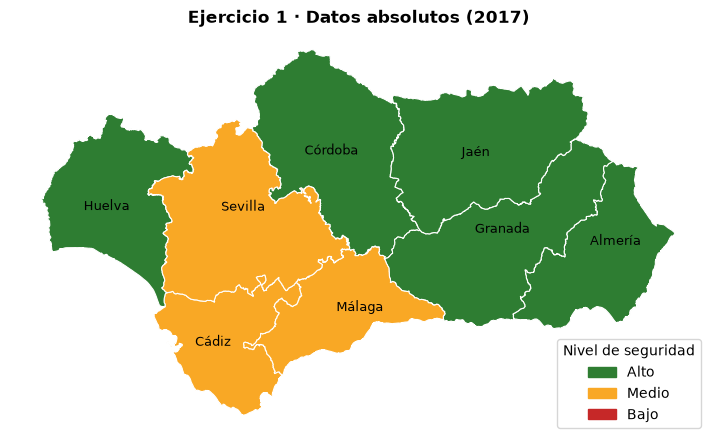

In [8]:
mapa_and = ah.load_map("mapas/andalucia/provincias_andalucia.shp", "andalucia")
ah.plot_classification(mapa_and, res1, "Ejercicio 1 · Datos absolutos (2017)")
plt.show()

---
## Ejercicio 2 · Andalucía normalizada por 10.000 habitantes

In [9]:
# Tasa = hechos / habitantes × 10.000
habitantes = ah.read_habitantes("datos/habitantes.xlsx")
tasas_and = ah.per_10000(datos_and, habitantes)
tasas_and

,Crímenes,Robos,Vehículos,Orden público,Drogas
Provincia,,,,,
Almería,0.3143,236.1873,28.7103,5.2884,3.6486
Cádiz,0.4896,213.2572,31.6623,5.7947,6.5652
Córdoba,0.2575,186.7689,21.7691,2.8193,1.9053
Granada,0.3473,207.7305,24.9528,3.9942,6.7511
Huelva,0.1521,213.4130,26.7955,2.9667,2.6434
Jaén,0.2711,120.3463,11.4479,2.7902,2.0568
Málaga,0.3421,272.0902,37.6080,4.8949,5.5082
Sevilla,0.4415,271.3194,49.6034,3.6758,2.1306


### Funciones de prioridad (Tablas 8, 9 y 10)
Se reutilizan los pesos del ejercicio 1.

In [10]:
CP2 = {"Crímenes": [0.26, 0.34, 0.41], "Robos": [194.29, 215.32, 261.32],
       "Vehículos": [22.95, 28.44, 36.20], "Orden público": [2.87, 3.86, 5.32],
       "Drogas": [2.06, 3.23, 6.25]}
puntos2 = {
    "Crímenes":      ([0, .10, .20, .26, .30, .34, .39, .41, .49], [.34, .13, .09, .05, .03, .03, .03, .03, .02]),
    "Robos":         ([0, 56.59, 113.18, 169.77, 194.29, 215.32, 226.35, 261.32, 282.94],
                      [.32, .14, .07, .05, .04, .03, .03, .03, .02]),
    "Vehículos":     ([0, 9.96, 19.93, 22.95, 28.44, 29.89, 36.20, 39.85, 49.82],
                      [.46, .12, .07, .06, .05, .05, .04, .03, .03]),
    "Orden público": ([0, 1.17, 2.33, 2.87, 3.50, 3.86, 4.66, 5.32, 5.83],
                      [.31, .15, .07, .07, .06, .05, .03, .03, .02]),
    "Drogas":        ([0, 1.36, 2.06, 2.73, 3.23, 4.09, 5.45, 6.25, 6.81],
                      [.39, .11, .09, .06, .05, .03, .02, .02, .02]),
}
funciones2 = {c: PriorityFunction(x, y, c) for c, (x, y) in puntos2.items()}
modelo2 = AHPSortII(CRITERIOS, pesos, funciones2, CP2)
modelo2.profiles_table()

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
Alto,0.0500,0.0400,0.0600,0.0700,0.0900,0.0633
Medio,0.0300,0.0300,0.0500,0.0500,0.0500,0.0390
Bajo,0.0300,0.0300,0.0400,0.0300,0.0200,0.0277


### Clasificación

In [11]:
res2 = modelo2.classify(tasas_and)
res2

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,|p − cp1|,|p − cp2|,|p − cp3|,Nivel de seguridad
Provincia,,,,,,,,,,
Almería,0.0300,0.0300,0.0500,0.0300,0.0403,0.0340,0.0293,0.0051,0.0062,Medio
Cádiz,0.0201,0.0310,0.0472,0.0207,0.0200,0.0225,0.0408,0.0166,0.0053,Bajo
Córdoba,0.0517,0.0431,0.0639,0.0700,0.0944,0.0658,0.0025,0.0267,0.0380,Alto
Granada,0.0300,0.0336,0.0564,0.0466,0.0200,0.0309,0.0324,0.0082,0.0031,Bajo
Huelva,0.1091,0.0309,0.0530,0.0685,0.0639,0.0823,0.0190,0.0432,0.0545,Alto
Jaén,0.0445,0.0675,0.1125,0.0700,0.0901,0.0658,0.0026,0.0268,0.0381,Alto
Málaga,0.0300,0.0250,0.0361,0.0300,0.0200,0.0271,0.0362,0.0119,0.0006,Bajo
Sevilla,0.0261,0.0254,0.0300,0.0551,0.0868,0.0467,0.0166,0.0076,0.0189,Medio


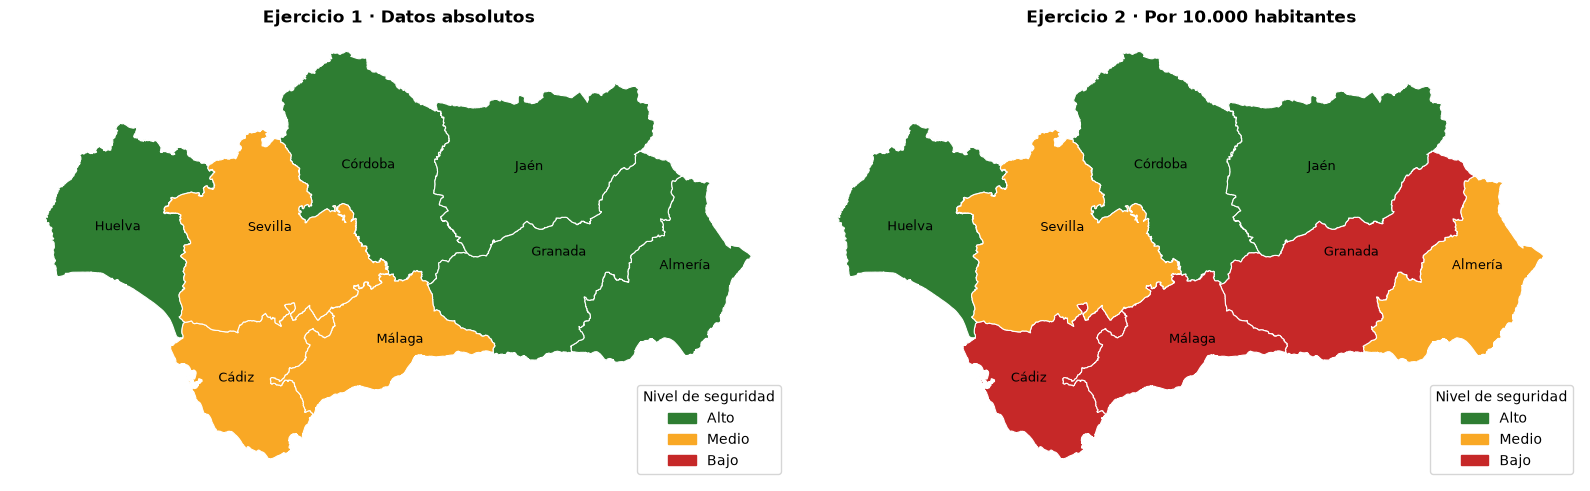

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ah.plot_classification(mapa_and, res1, "Ejercicio 1 · Datos absolutos", ax=axes[0])
ah.plot_classification(mapa_and, res2, "Ejercicio 2 · Por 10.000 habitantes", ax=axes[1])
plt.tight_layout(); plt.show()

Los CP y RP de las Tablas 8 y 9 están calculados con la población de 2017 (ver ejercicio 3), mientras que
`habitantes.xlsx` tiene una población posterior. Comparación de ambas tasas:

In [13]:
tasas_and_2017 = ah.read_nacional_2017("datos/Datos_nacionales_2017_por_10000_ES.xlsx").loc[datos_and.index]
res2_2017 = modelo2.classify(tasas_and_2017)
pd.DataFrame({"habitantes.xlsx": res2["Nivel de seguridad"], "Población 2017": res2_2017["Nivel de seguridad"]})

,habitantes.xlsx,Población 2017
Provincia,,
Almería,Medio,Bajo
Cádiz,Bajo,Bajo
Córdoba,Alto,Alto
Granada,Bajo,Bajo
Huelva,Alto,Alto
Jaén,Alto,Alto
Málaga,Bajo,Bajo
Sevilla,Medio,Medio


---
## Ejercicio 3 · España (2017)

### a) Verificación de la normalización
El fichero nacional ya viene en tasas por 10.000 habitantes. Se comprueba con Andalucía: población implícita
= hechos × 10.000 / tasa, que debe ser igual en los cinco criterios.

In [14]:
nac17 = ah.read_nacional_2017("datos/Datos_nacionales_2017_por_10000_ES.xlsx")
(datos_and * 10000 / nac17.loc[datos_and.index]).round(0)

,Crímenes,Robos,Vehículos,Orden público,Drogas
Provincia,,,,,
Almería,706672.0000,706672.0000,706672.0000,706672.0000,706672.0000
Cádiz,1239435.0000,1239435.0000,1239435.0000,1239435.0000,1239435.0000
Córdoba,788219.0000,788219.0000,788219.0000,788219.0000,788219.0000
Granada,912938.0000,912938.0000,912938.0000,912938.0000,912938.0000
Huelva,518930.0000,518930.0000,518930.0000,518930.0000,518930.0000
Jaén,643484.0000,643484.0000,643484.0000,643484.0000,643484.0000
Málaga,1630615.0000,1630615.0000,1630615.0000,1630615.0000,1630615.0000
Sevilla,1939527.0000,1939527.0000,1939527.0000,1939527.0000,1939527.0000


### b) Justificación de los CP y RP
CP = percentiles 20, 50 y 80 de las tasas; RP = 6 puntos equiespaciados entre 0 y el máximo.

In [15]:
cp_calc, rp_calc = ah.derive_profiles(nac17)
display(cp_calc.round(2))
rp_calc.round(2)

,Crímenes,Robos,Vehículos,Orden público,Drogas
CP1 (Alto),0.1700,129.1800,7.4200,2.7300,1.4600
CP2 (Medio),0.2500,179.3700,13.6900,3.3800,2.0000
CP3 (Bajo),0.3600,268.9900,30.9400,4.5200,2.7700


,Crímenes,Robos,Vehículos,Orden público,Drogas
RP1,0.0000,0.0000,0.0000,0.0000,0.0000
RP2,0.1500,81.2900,10.8000,1.1800,1.3600
RP3,0.3000,162.5900,21.5900,2.3500,2.7300
RP4,0.4400,243.8800,32.3900,3.5300,4.0900
RP5,0.5900,325.1700,43.1900,4.7000,5.4500
RP6,0.7400,406.4600,53.9800,5.8800,6.8100


### Funciones de prioridad (Tablas 11–14) y clasificación

In [16]:
CP3 = {"Crímenes": [.17, .25, .36], "Robos": [129.18, 179.38, 268.99], "Vehículos": [7.42, 13.69, 30.94],
       "Orden público": [2.73, 3.38, 4.52], "Drogas": [1.46, 2.00, 2.77]}
RP3 = {"Crímenes": [0, .15, .30, .44, .59, .74], "Robos": [0, 81.29, 162.59, 243.88, 325.17, 406.46],
       "Vehículos": [0, 10.80, 21.59, 32.39, 43.19, 53.98], "Orden público": [0, 1.18, 2.35, 3.53, 4.70, 5.88],
       "Drogas": [0, 1.36, 2.73, 4.09, 5.45, 6.81]}
Y13 = {"Crímenes": [.336, .132, .086, .032, .026, .023], "Robos": [.32, .139, .074, .047, .031, .022],
       "Vehículos": [.459, .124, .069, .048, .034, .026], "Orden público": [.308, .149, .071, .06, .032, .023],
       "Drogas": [.385, .112, .062, .033, .023, .018]}
Y14 = {"Crímenes": [.125, .099, .061], "Robos": [.101, .068, .042], "Vehículos": [.229, .109, .051],
       "Orden público": [.067, .061, .036], "Drogas": [.109, .089, .061]}
funciones3 = {c: PriorityFunction(RP3[c] + CP3[c], Y13[c] + Y14[c], c) for c in CRITERIOS}
modelo3 = AHPSortII(CRITERIOS, pesos, funciones3, CP3)
modelo3.profiles_table()

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global
Alto,0.1250,0.1010,0.2290,0.0670,0.1090,0.1175
Medio,0.0990,0.0680,0.1090,0.0610,0.0890,0.0898
Bajo,0.0610,0.0420,0.0510,0.0360,0.0610,0.0560


In [17]:
res3 = modelo3.classify(nac17)
res3.sort_values("Global", ascending=False)

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,|p − cp1|,|p − cp2|,|p − cp3|,Nivel de seguridad
Provincia,,,,,,,,,,
Soria,0.3360,0.1022,0.2289,0.1002,0.1366,0.2277,0.1102,0.1379,0.1717,Alto
Palencia,0.3360,0.1213,0.3376,0.0536,0.1064,0.2213,0.1038,0.1315,0.1653,Alto
Burgos,0.2980,0.0776,0.1138,0.0461,0.0866,0.1813,0.0638,0.0915,0.1253,Alto
Cuenca,0.2676,0.0768,0.1052,0.1035,0.0997,0.1770,0.0595,0.0872,0.1210,Alto
Lugo,0.2137,0.1248,0.1560,0.0683,0.1076,0.1566,0.0391,0.0668,0.1006,Alto
Valladolid,0.0831,0.0717,0.1758,0.0793,0.2733,0.1401,0.0226,0.0503,0.0841,Alto
Segovia,0.1596,0.1033,0.2620,0.0635,0.0982,0.1322,0.0147,0.0424,0.0762,Alto
León,0.1109,0.0721,0.1272,0.0660,0.2135,0.1322,0.0147,0.0424,0.0762,Alto
Ávila,0.1667,0.1007,0.2217,0.0629,0.0847,0.1293,0.0118,0.0395,0.0733,Alto


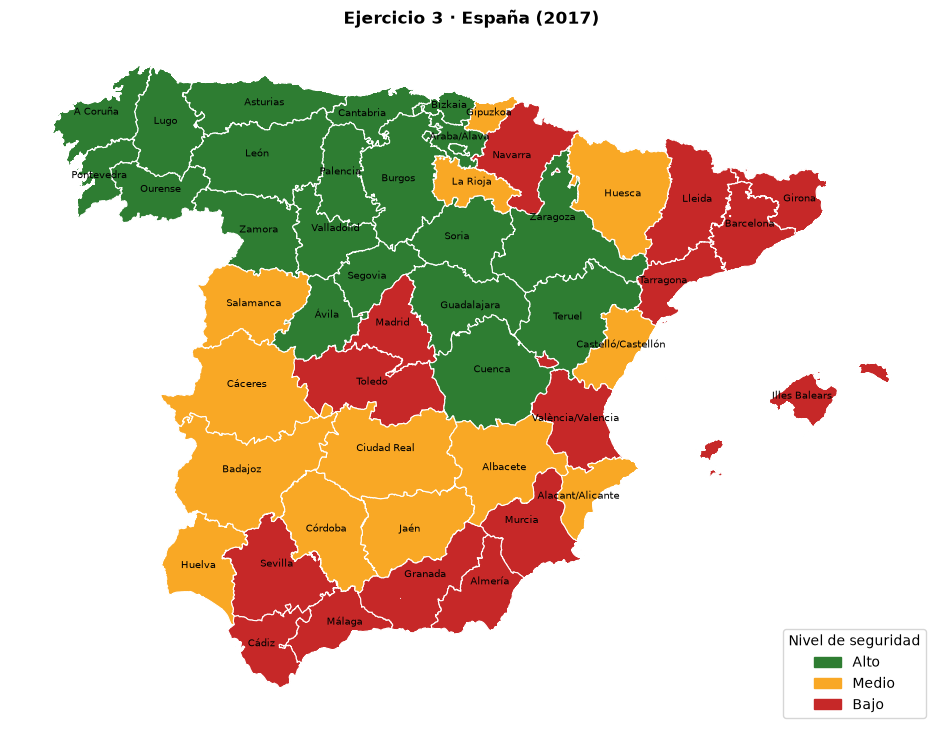

,Global,Nivel de seguridad
Provincia,,
Palmas (Las),0.0611,Bajo
Santa Cruz de Tenerife,0.0544,Bajo


In [18]:
mapa_esp = ah.load_map("mapas/espana/provincias_espana.shp", "espana")
fig, ax = plt.subplots(figsize=(12, 9))
ah.plot_classification(mapa_esp, res3, "Ejercicio 3 · España (2017)", ax=ax)
plt.show()
# El mapa no incluye Canarias:
res3.loc[["Palmas (Las)", "Santa Cruz de Tenerife"], ["Global", "Nivel de seguridad"]]

---
## Ejercicio 4 · España 2023 con la calibración de 2017
Mismos pesos, CP, RP y funciones de 2017. Los valores por encima del máximo de 2017 se truncan
(reciben la prioridad del último punto de la función).

In [19]:
nac23 = ah.read_nacional_2023("datos/Datos_nacionales_2023_por_10000_ES.xlsx")
res4 = modelo3.classify(nac23)
res4.sort_values("Global", ascending=False)

,Crímenes,Robos,Vehículos,Orden público,Drogas,Global,|p − cp1|,|p − cp2|,|p − cp3|,Nivel de seguridad,Truncado en
Provincia,,,,,,,,,,,
Teruel,0.2354,0.1713,0.3581,0.0663,0.0919,0.1769,0.0594,0.0871,0.1209,Alto,
Ourense,0.2020,0.1266,0.1136,0.0501,0.1609,0.1618,0.0443,0.0720,0.1058,Alto,
Segovia,0.2484,0.1255,0.1934,0.0241,0.0583,0.1559,0.0384,0.0661,0.0999,Alto,
Burgos,0.1837,0.1026,0.1203,0.0241,0.0781,0.1254,0.0079,0.0356,0.0694,Alto,
Cáceres,0.1303,0.1425,0.2942,0.0617,0.0799,0.1181,0.0006,0.0283,0.0621,Alto,
Bizkaia,0.1357,0.0549,0.3427,0.0248,0.0941,0.1159,0.0016,0.0261,0.0599,Alto,
Salamanca,0.1310,0.0991,0.0903,0.0612,0.0872,0.1057,0.0117,0.0160,0.0498,Alto,
Cantabria,0.1250,0.0971,0.1285,0.0314,0.0913,0.1026,0.0149,0.0128,0.0466,Medio,
Asturias,0.1124,0.1192,0.1984,0.0291,0.0931,0.1025,0.0150,0.0127,0.0465,Medio,


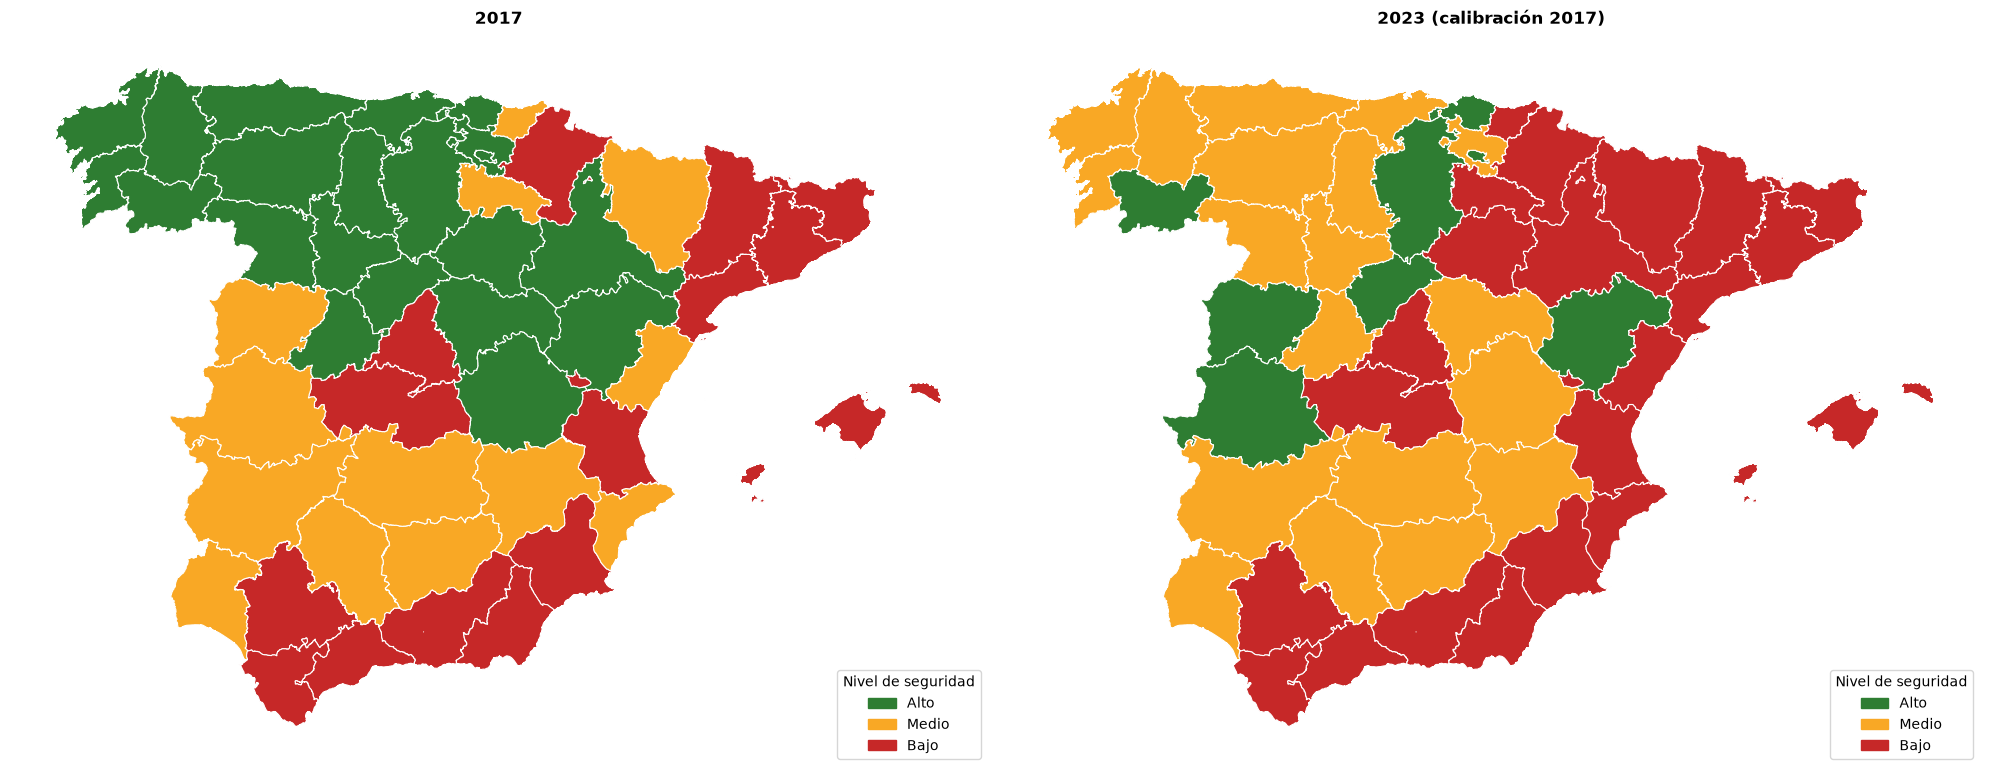

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
ah.plot_classification(mapa_esp, res3, "2017", ax=axes[0], labels=False)
ah.plot_classification(mapa_esp, res4, "2023 (calibración 2017)", ax=axes[1], labels=False)
plt.tight_layout(); plt.show()

### Tabla de transición y matriz de cambios

In [21]:
nombre17 = {ah.ine_code(p): p for p in res3.index}
transicion = pd.DataFrame({
    "Clase 2017": [res3.loc[nombre17[ah.ine_code(p)], "Nivel de seguridad"] for p in res4.index],
    "Clase 2023": res4["Nivel de seguridad"].values,
}, index=[nombre17[ah.ine_code(p)] for p in res4.index]).sort_index()
orden = {"Alto": 0, "Medio": 1, "Bajo": 2}
transicion["Cambio"] = ["=" if a == b else ("Empeora" if orden[b] > orden[a] else "Mejora")
                        for a, b in zip(transicion["Clase 2017"], transicion["Clase 2023"])]
transicion

,Clase 2017,Clase 2023,Cambio
Albacete,Medio,Medio,=
Alicante/Alacant,Medio,Bajo,Empeora
Almería,Bajo,Bajo,=
Araba/Álava,Alto,Medio,Empeora
Asturias,Alto,Medio,Empeora
Badajoz,Medio,Medio,=
Balears (Illes),Bajo,Bajo,=
Barcelona,Bajo,Bajo,=
Bizkaia,Alto,Alto,=
Burgos,Alto,Alto,=


In [22]:
pd.crosstab(pd.Categorical(transicion["Clase 2017"], ah.CLASES),
            pd.Categorical(transicion["Clase 2023"], ah.CLASES),
            rownames=["2017"], colnames=["2023"], margins=True, margins_name="Total", dropna=False)

2023,Alto,Medio,Bajo,Total
2017,,,,
Alto,5,13,2,20
Medio,2,6,5,13
Bajo,0,0,17,17
Total,7,19,24,50
